<br>


# `#01: Fourier Transformation on image:`

<br>

 
i) The spatial space of an image refers to how pixels, coordinates, or visual elements are arranged across a
2D or 3D physical coordinate(x,y) or (x,y,z) grid.

ii) Normally in spatial sapce we do, image blur, image sharping, smoothing etc. 

iii) If a task, like below here we can't solve by spatial space operation then we do domain transform.



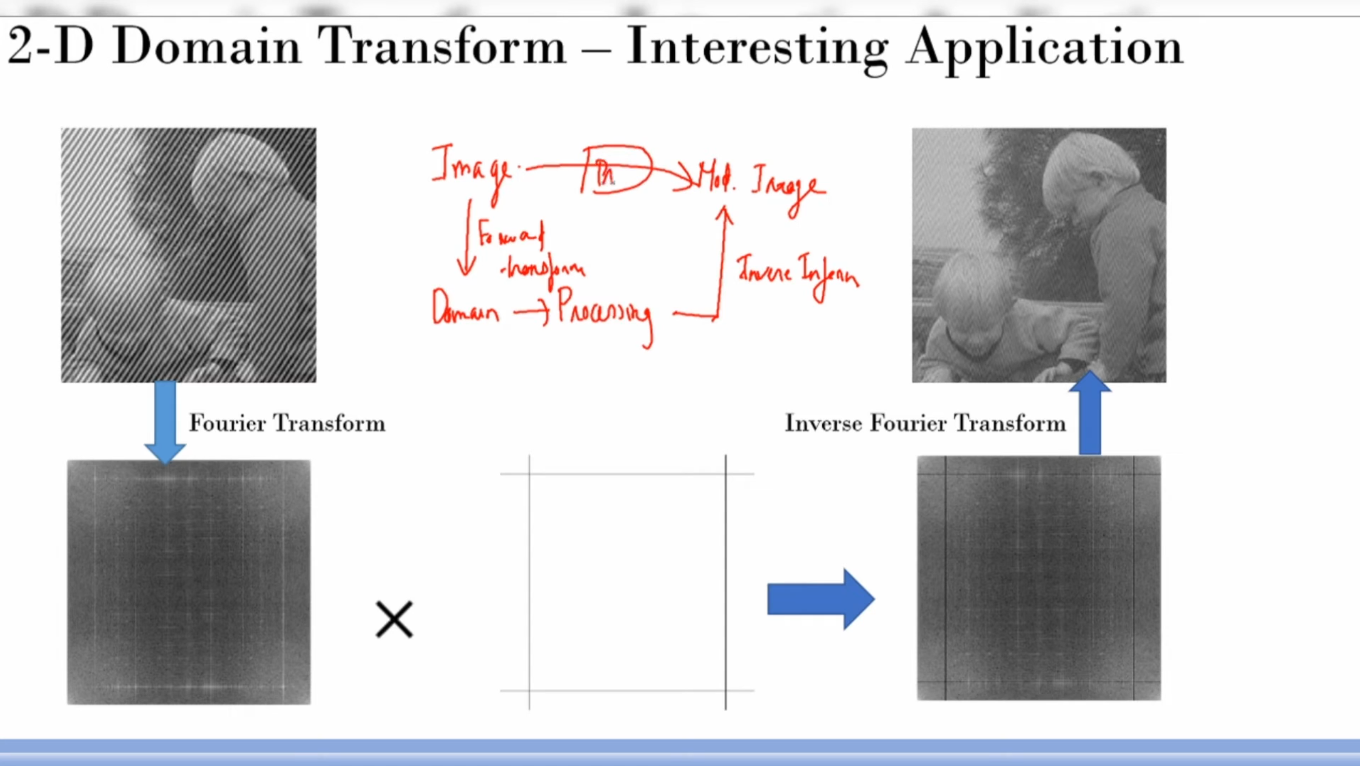

In [1]:

from IPython.display import Image

print(""" 
i) The spatial space of an image refers to how pixels, coordinates, or visual elements are arranged across a
2D or 3D physical coordinate(x,y) or (x,y,z) grid.

ii) Normally in spatial sapce we do, image blur, image sharping, smoothing etc. 

iii) If a task, like below here we can't solve by spatial space operation then we do domain transform.
""")

Image("../../img/img20.png")




i) f(x,y) => Is the actual funtion, like, image in spitial space. 

ii) Sai(u,v,x,y) => called a basis funtion. 



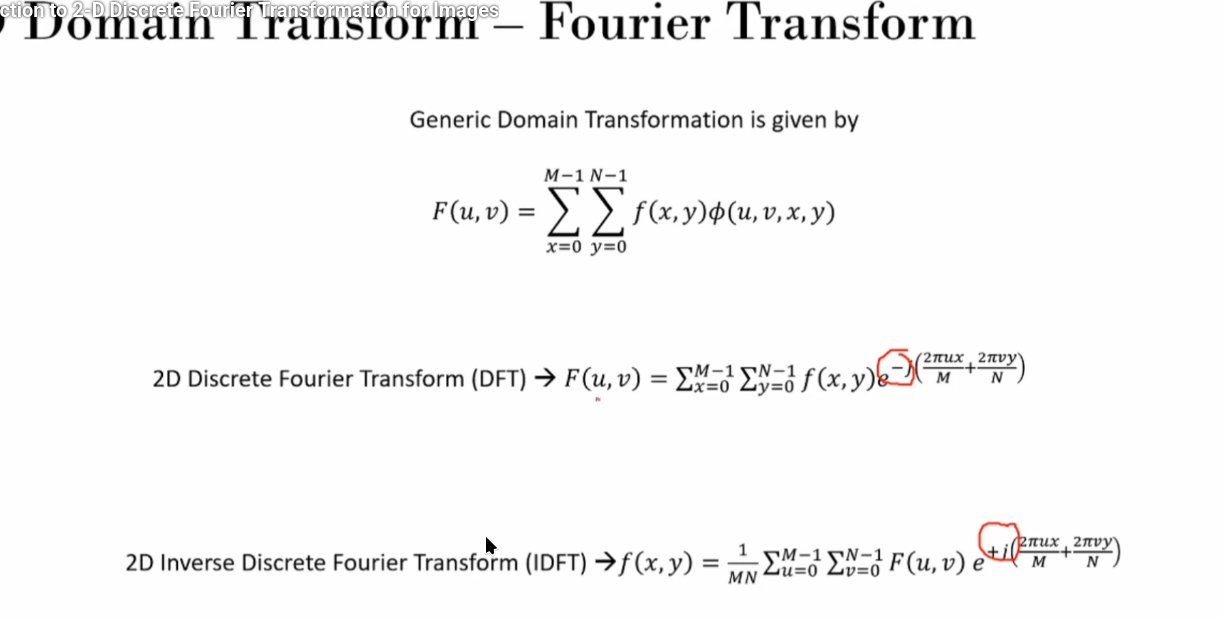

In [2]:

print("""

i) f(x,y) => Is the actual funtion, like, image in spitial space. 

ii) Sai(u,v,x,y) => called a basis funtion. 
""")
Image("../../img/img21.png")

In [3]:
print(
"""
Q1)  
"""
)


Q1)  



In [4]:
import numpy as np

# Input 1-D vectors
x = np.array([1, 2, 3])  # Length 3 -> output column will be 3
y = np.array([10, 20])  # Length 2 -> output row will be two

# Create meshgrid
X, Y = np.meshgrid(x, y)

print("X values:\n", X)
print("\nY values:\n", Y)


X values:
 [[1 2 3]
 [1 2 3]]

Y values:
 [[10 10 10]
 [20 20 20]]


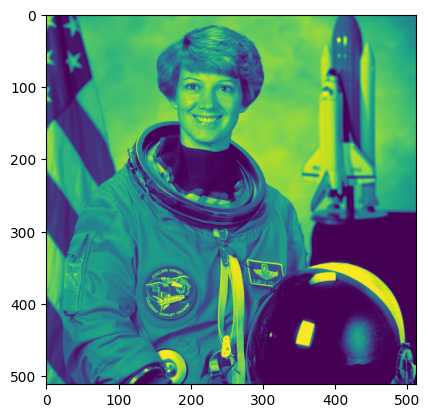

512 512


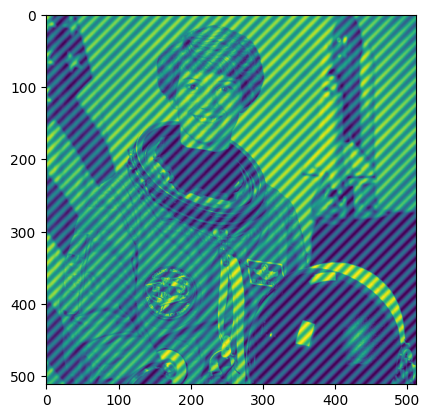

In [5]:
import numpy as np 
import matplotlib.pyplot as plt 
from skimage import data, color, filters

# 1. create an image like in slide1:
img = color.rgb2gray(data.astronaut())
plt.imshow(img)
plt.show()

W,H = img.shape
print(W,H)
# x = (512x512)matrix every pixel-row number matrix
# y= (512x512)matrix every pixel-column number matrix
# np.arrange(512) = [0,1,2,3,....511]
x,y = np.meshgrid(np.arange(W),np.arange(H))

# A =  0.3 -> noise is high or low
# A.sin(2*pi*f*t+phase)
# f = 30: 
"""
we have a 4x4 martix then:
x,y = meshgrid(np.arange(4),np.arange(4))
x = [
[0,1,2,3],
[0,1,2,3],
[0,1,2,3],
[0,1,2,3],
] 
y = [
    [0,0,0,0],
    [1,1,1,1],
    [2,2,2,2],
    [3,3,3,3],
]

x+y = [
    [0,1,2,3],
    [1,2,3,4],
    [2,3,4,5],
    [3,4,5,6]
]
here, xy like a patten, 
why sin? cause, if we only add then the intensity will go upto: 1k + after addition{511+511}= so 
we normalize them. (x/W+y/H) give us continous value, for making this type of 
image, we need an up and down. So, sin do that.
"""
noisy = img + 0.3*np.sin(2*np.pi*30*(x/W + y/H))
plt.imshow(noisy)
plt.show()


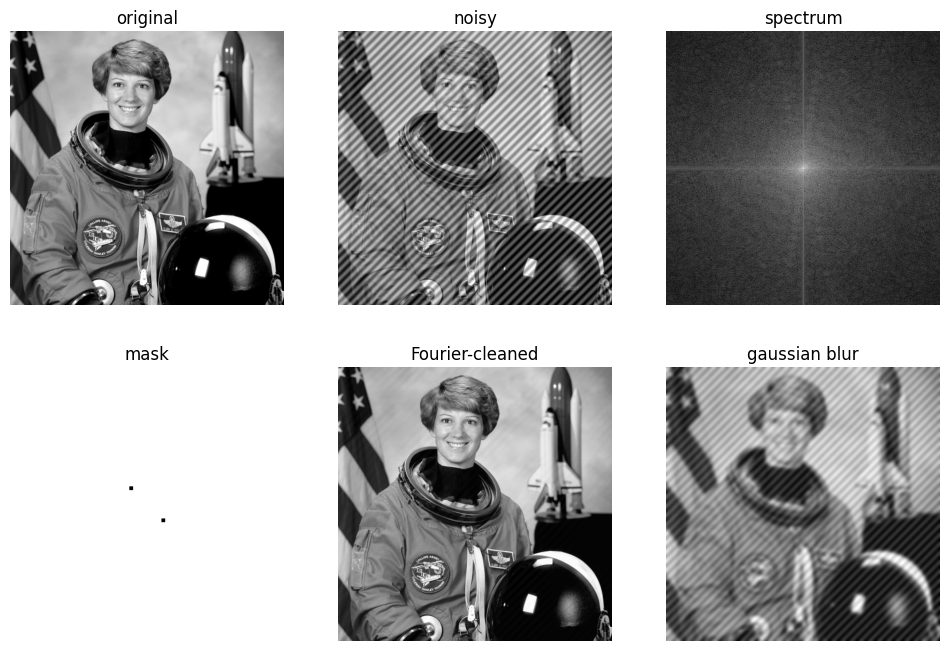

In [6]:

# fft -> for 1 dimentional 
# fft2 -> for 2 dimentional
# fft2 -> returns = complex number:
F = np.fft.fftshift(np.fft.fft2(noisy))          

mask = np.ones((H, W))
cy, cx = H//2, W//2

for dy, dx in [(30, 30), (-30, -30)]:                  
    mask[cy+dy-3:cy+dy+4, cx+dx-3:cx+dx+4] = 0
clean = np.real(np.fft.ifft2(np.fft.ifftshift(F*mask)))

# apply bluring:
blur = filters.gaussian(noisy, sigma=3)                

# draw image:
imgs  = [img, noisy, np.log1p(np.abs(F)), mask, clean, blur]
names = ['original', 'noisy', 'spectrum', 'mask', 'Fourier-cleaned', 'gaussian blur']
fig, ax = plt.subplots(2, 3, figsize=(12, 8))
for a, im, t in zip(ax.flat, imgs, names):
    a.imshow(im, cmap='gray'); a.set_title(t); a.axis('off')
plt.show()


<br>

# 2. Disadvantage of Short-Time-Fourier Analysis:

<br>


- **01_basic.ipynb**, we see that, we have fourier analysis but it's continous then we modify it for discreate known as discreate fourier transformation. But the problem with fourier transformation is that there is no time domain. So, we introduce a windows mechanism to caputue the time. In, short time fourier analysis. For short time fourier analysis there are two version i) continous another one is ii) discreate. 


<br>


<br>



<br>

<br>

# 2. Hadamard Transformation

<br>


i) We know in general fourier transormation formula,  Sai(u,v,x,y) => called a basis funtion. 

ii) In fourier transformation we use, e^it= sin(t) + cos(t).

iii) Instead of using sine and cosine we use a square wave, here as
we are working with discreate we work with matrix bro. We called it 
hadamard metrix.




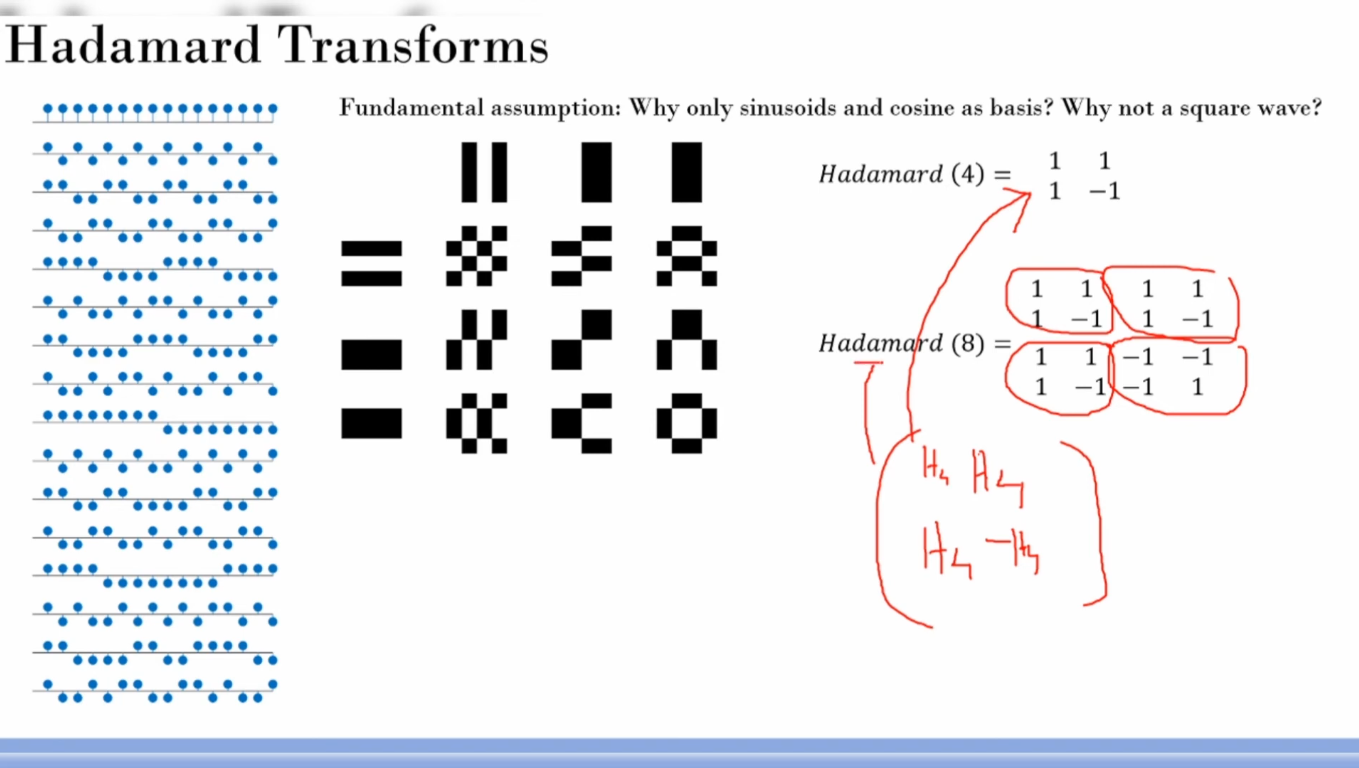

In [14]:


print("""
i) We know in general fourier transormation formula,  Sai(u,v,x,y) => called a basis funtion. 

ii) In fourier transformation we use, e^it= sin(t) + cos(t).

iii) Instead of using sine and cosine we use a square wave, here as
we are working with discreate we work with matrix bro. We called it 
hadamard metrix.

""")
Image("../../img/img22.png")



In [ ]:

from scipy.linalg import hadamard
hadamard(4)


array([[ 1,  1,  1,  1],
       [ 1, -1,  1, -1],
       [ 1,  1, -1, -1],
       [ 1, -1, -1,  1]])